<a href="https://colab.research.google.com/github/muneirah/IS316_Group15/blob/main/Copy_of_Project_IS316_group15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
#first we import pandas so we can use it and load the database
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
file1 = files.upload()
istanbulApartmentForRent_project = next(iter(file1))

df = pd.read_csv(istanbulApartmentForRent_project)
df.head()



Saving 15.istanbulApartmentForRent_project.csv to 15.istanbulApartmentForRent_project (1).csv


,district,neighborhood,room,living room,area (m2),age,floor,price
0,Bakırköy,Kartaltepe Mah.,2.0,1,90.0,45.0,3.0,260
1,Çekmeköy,Merkez Mah.,3.0,1,150.0,11.0,0.0,850
2,Fatih,Mevlanakapı Mah.,2.0,1,68.0,35.0,1.0,130
3,Beyoğlu,Kılıçali Paşa Mah.,2.0,1,80.0,0.0,3.0,790
4,Bahçelievler,Bahçelievler Mah.,2.0,1,90.0,1.0,-2.0,400


In [ ]:
NoRow = df.shape[0]
NoCol = df.shape[1]
print("number of rows" , NoRow , "number of columns " , NoCol)


number of rows 11627 number of columns  8


count    1.162700e+04
mean     4.431693e+04
std      2.699498e+05
min      4.000000e+01
25%      1.500000e+03
50%      2.200000e+04
75%      3.999950e+04
max      2.300000e+07
Name: price, dtype: float64
skewness  58.587166500134735


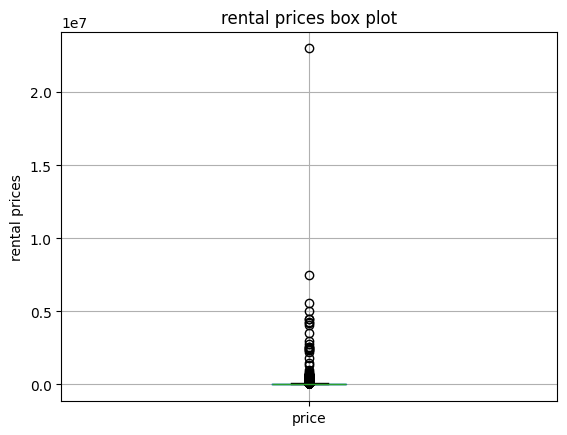

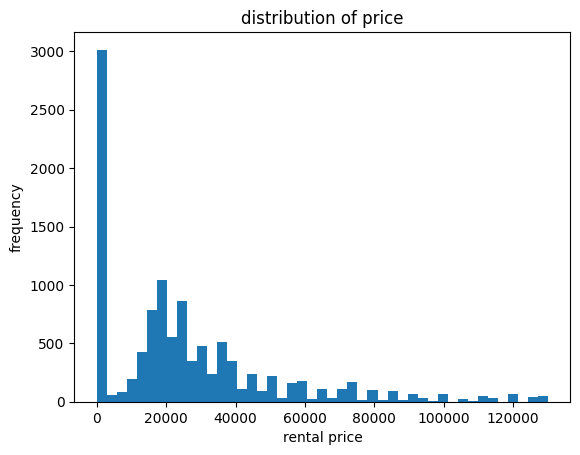

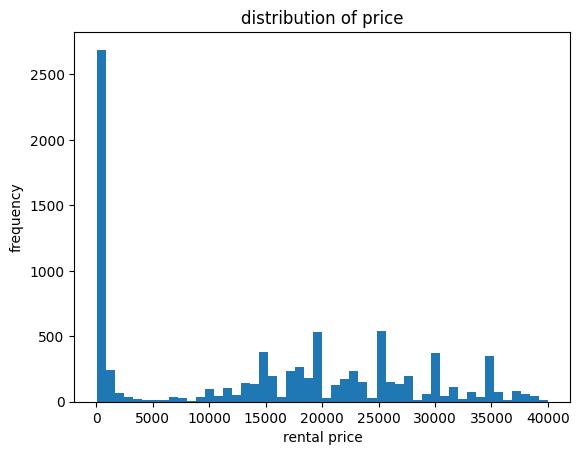

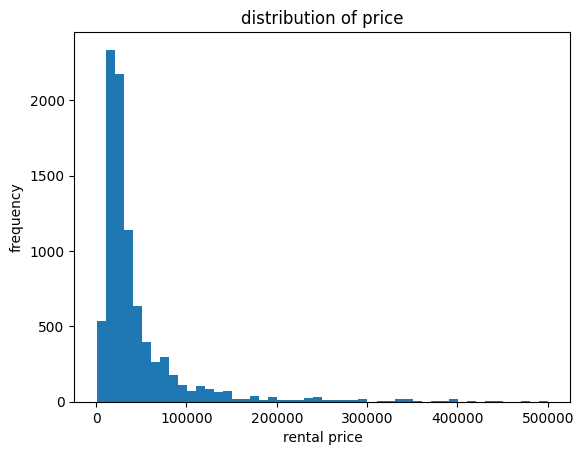

In [ ]:
#target variable distrubition (the price)

print(df['price'].describe())
print("skewness ",df['price'].skew())
import matplotlib.pyplot as plt
df.boxplot(column = 'price')
plt.title('rental prices box plot')
plt.ylabel('rental prices')
plt.show()
plt.hist(df.loc[df['price'] <= df['price'].quantile(0.95) , 'price'], bins= 45)
plt.title('distribution of price')
plt.xlabel('rental price')
plt.ylabel('frequency')
plt.show()
plt.hist(df.loc[df['price'] <= df['price'].quantile(0.75) , 'price'], bins= 50 )
plt.title('distribution of price')
plt.xlabel('rental price')
plt.ylabel('frequency')
plt.show()
plt.hist(df.loc[(df['price'] >= 1000) & (df['price'] <=500000 ), 'price'] , bins= 50 )
plt.title('distribution of price')
plt.xlabel('rental price')
plt.ylabel('frequency')
plt.show()


In [ ]:
df.info()
#shows the data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11627 entries, 0 to 11626
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   district      11627 non-null  object 
 1   neighborhood  11279 non-null  object 
 2   room          11395 non-null  float64
 3   living room   11627 non-null  int64  
 4   area (m2)     11279 non-null  float64
 5   age           11279 non-null  float64
 6   floor         11395 non-null  float64
 7   price         11627 non-null  int64  
dtypes: float64(4), int64(2), object(2)
memory usage: 726.8+ KB


In [ ]:
df.isnull().sum()
#how much values are null for each column

,0
district,0
neighborhood,348
room,232
living room,0
area (m2),348
age,348
floor,232
price,0


In [ ]:
print("number of duplicates is " , df.duplicated().sum())

number of duplicates is  182


In [ ]:
df.describe()
#the descriptive stastics of the datasetm

,room,living room,area (m2),age,floor,price
count,11395.000000,11627.000000,11279.000000,11279.000000,11395.000000,1.162700e+04
mean,2.286968,1.175884,141.309779,17.883855,3.835015,4.431693e+04
std,2.077987,10.026617,1683.263245,23.576794,4.742888,2.699498e+05
min,1.000000,0.000000,6.000000,0.000000,-3.000000,4.000000e+01
25%,2.000000,1.000000,80.000000,5.000000,1.000000,1.500000e+03
50%,2.000000,1.000000,100.000000,15.000000,2.000000,2.200000e+04
75%,3.000000,1.000000,136.000000,29.000000,4.000000,3.999950e+04
max,180.000000,965.000000,178158.000000,1864.000000,21.000000,2.300000e+07


In [ ]:
#creating a data dictionary describin each variable and their types and valid values and inteded roles
dictionary = pd.DataFrame({
    'variable' : df.columns ,
    'meaning': [
        'district is what district the property is located',
        'neighborhood is what neighborhood the property is located',
        'number of rooms',
        'number of living rooms',
        'the propertys area in m2',
        'age of the property in years',
        'which floor the propertys in',
        'rental price in TRY of the property'

    ],

    'data type ' : df.dtypes.astype(str).values,
    'valid values':
    [
        'district names',
        'neighborhood names',
        'non negative whole number',
        'non negative whole number',
        'positive numeric value in the unit m2',
        'non negative numeric value in the unit years',
        'whole numbers ',
        'positive numeric values'
    ],

    'intended role ':
    [
        'predictor'        ,
        'predictor',
        'predictor',
        'predictor',
        'predictor',
        'predictor',
        'predictor',
        'target'

    ],
    'missing values' : df.isnull().sum().values,
    'unique values ' : df.nunique().values
})
display(dictionary)

,variable,meaning,data type,valid values,intended role,missing values,unique values
0,district,district is what district the property is located,object,district names,predictor,0,38
1,neighborhood,neighborhood is what neighborhood the property...,object,neighborhood names,predictor,348,590
2,room,number of rooms,float64,non negative whole number,predictor,232,18
3,living room,number of living rooms,int64,non negative whole number,predictor,0,16
4,area (m2),the propertys area in m2,float64,positive numeric value in the unit m2,predictor,348,329
5,age,age of the property in years,float64,non negative numeric value in the unit years,predictor,348,81
6,floor,which floor the propertys in,float64,whole numbers,predictor,232,25
7,price,rental price in TRY of the property,int64,positive numeric values,target,0,656


In [ ]:
# DETECT: count the missing values per column and per row.
# WHY: to know which columns have a problem, how big it is and whether a row is missing
# one value (easy to fill) or many (hard to use).
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})
print(missing[missing.missing_count > 0])

#count missing valuse per row
miss_cols = ["neighborhood", "room", "area (m2)", "age", "floor"]
n_miss = df[miss_cols].isna().sum(axis=1)
print("Rows with >=1 missing:", (n_miss >= 1).sum())
print("Rows with exactly 1  :", (n_miss == 1).sum())
print("Rows with 2+         :", (n_miss >= 2).sum())

print("Median price, no missing :", df.loc[n_miss == 0, "price"].median())
print("Median price, any missing:", df.loc[n_miss >= 1, "price"].median())


              missing_count  missing_pct
neighborhood            348         2.99
room                    232         2.00
area (m2)               348         2.99
age                     348         2.99
floor                   232         2.00
Rows with >=1 missing: 1440
Rows with exactly 1  : 1375
Rows with 2+         : 65
Median price, no missing : 22000.0
Median price, any missing: 23000.0


In [ ]:
# DETECT: find the rows that are exact copies of other rows (all 8 columns identical)
dup_all = df.duplicated(keep=False)
dup_extra = df.duplicated(keep="first")
print("Rows in duplicate groups:", dup_all.sum())
print("Extra copies:", dup_extra.sum(), f"({dup_extra.mean()*100:.2f}%)")
#look for duplicate groups
groups = df[dup_all].groupby(list(df.columns), dropna=False).size()
print("Groups:", len(groups))
print(groups.value_counts().sort_index())
print(df[dup_extra]["district"].value_counts().head(5))
#duplicate only with diffrent price
features = [c for c in df.columns if c != "price"]
g = df.groupby(features, dropna=False)["price"].agg(["size", "nunique"])
print("Same-feature groups:", (g["size"] > 1).sum())
print("...with different prices:", ((g["size"] > 1) & (g["nunique"] > 1)).sum())


Rows in duplicate groups: 342
Extra copies: 182 (1.57%)
Groups: 160
2    144
3     11
4      4
5      1
Name: count, dtype: int64
district
Şişli         30
Sarıyer       24
Kağıthane     17
Beşiktaş      12
Üsküdar       10
Name: count, dtype: int64
Same-feature groups: 394
...with different prices: 255


In [ ]:
# DECIDE: remove only the EXACT duplicates and keep the first copy of each
#save size
rows_before = len(df)
#remove duplicates
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print("Before:", rows_before, "| After:", len(df), "| Removed:", rows_before - len(df))
#assert stops the code with an error if any duplicate is still left
assert df.duplicated().sum() == 0


Before: 11627 | After: 11445 | Removed: 182


In [ ]:
#DECIDE: remove the rows with a missing neighborhood and fill the other columns with the median
missing_before = df.isna().sum()
#deletes only rows with empty neighborhood
rows_before = len(df)
df = df.dropna(subset=["neighborhood"]).reset_index(drop=True)
print("Rows removed (missing neighborhood):", rows_before - len(df),
      f"({(rows_before - len(df)) / rows_before * 100:.2f}%)")
#fill other rows use median
for col in ["room", "area (m2)", "age", "floor"]:
    median_value = df[col].median()          # the typical value of the column
    df[col] = df[col].fillna(median_value)   # fill the empty cells with it
    print(f"{col}: filled with median = {median_value}")
 #show before and after
print(pd.DataFrame({"before": missing_before, "after": df.isna().sum()}))
assert df.isna().sum().sum() == 0, "There are still missing values!"
print("Final shape:", df.shape)

Rows removed (missing neighborhood): 348 (3.04%)
room: filled with median = 2.0
area (m2): filled with median = 100.0
age: filled with median = 15.0
floor: filled with median = 2.0
              before  after
district           0      0
neighborhood     348      0
room             232      0
living room        0      0
area (m2)        348      0
age              347      0
floor            232      0
price              0      0
Final shape: (11097, 8)


In [ ]:
#DETECT: check the two text columns for extra spaces at the start or end of the values
for col in ["district", "neighborhood"]:
    s = df[col].dropna()
    print(col, "- values with extra spaces:", (s != s.str.strip()).sum(), "of", len(s))

district - values with extra spaces: 11097 of 11097
neighborhood - values with extra spaces: 11097 of 11097


In [ ]:
# DECIDE: remove the extra spaces and keep the Turkish letters as they are
for col in ["district", "neighborhood"]:
    df[col] = df[col].str.strip()

assert (df["district"] != df["district"].str.strip()).sum() == 0
assert (df["neighborhood"].dropna() != df["neighborhood"].dropna().str.strip()).sum() == 0
print(df["district"].nunique(), "districts |", df["neighborhood"].nunique(), "neighborhoods")

38 districts | 590 neighborhoods


In [ ]:
#invalid data types/formats
numeric_cols = ['room', 'living room', 'area (m2)', 'age', 'floor', 'price']
integer_cols = ['room', 'living room', 'age', 'floor']
text_cols = ['district', 'neighborhood']

format_issues = []

# Check numeric columns and record errors
for col in numeric_cols:
    converted = pd.to_numeric(df[col], errors='coerce')
    problems = df[col].notna() & converted.isna()

    print(f"\n{col}: {problems.sum()} possible type/format errors")
    display(df.loc[problems, [col]])

    for idx in df.index[problems]:
        format_issues.append({
            'row index': idx,
            'column': col,
            'original value': df.loc[idx, col],
            'issue type': 'incorrect data type/format',
            'reason': 'value cannot be converted directly to a number'
        })

    df[col] = converted

# Check text columns
for col in text_cols:
    problems = []

    for idx, value in df[col].items():
        if pd.notna(value) and not isinstance(value, str):
            problems.append(idx)

    print(f"\n{col}: {len(problems)} possible data type errors")
    display(df.loc[problems, [col]])

# Restore integer types
for col in integer_cols:
    df[col] = df[col].astype('Int64')

# Display the format error report
format_report = pd.DataFrame(format_issues)
display(format_report)

# Display final data types
print(df[['district', 'neighborhood'] + numeric_cols].dtypes)





room: 0 possible type/format errors


,room



living room: 0 possible type/format errors


,living room



area (m2): 0 possible type/format errors


,area (m2)


... (8 outputs left out)


neighborhood: 0 possible data type errors


,neighborhood


""


district         object
neighborhood     object
room              Int64
living room       Int64
area (m2)       float64
age               Int64
floor             Int64
price             int64
dtype: object


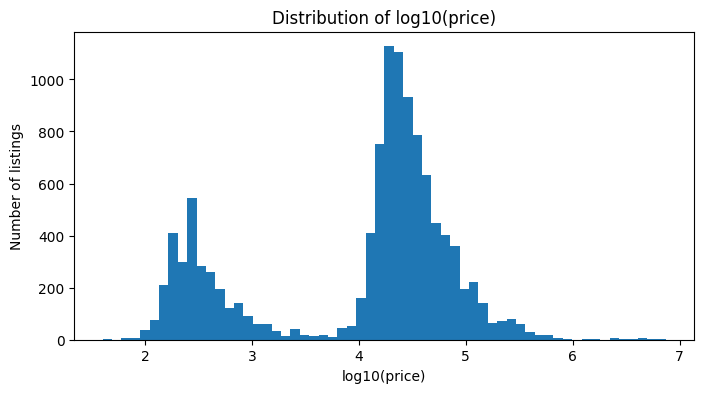

Rows with price < 1000: 2652 (23.9%)
Median price per m2, price < 1000 : 2.9
Median price per m2, price >= 1000: 290.7


In [ ]:
# ===== D4 (part 1): price scale =====
# DETECT
# We draw a histogram of log10(price). We use the log because prices go from 40 to millions,
# and on a normal scale we could not see the shape.
# If we see two separate humps, the price column may have two different scales mixed together.
plt.figure(figsize=(8, 4))
plt.hist(np.log10(df["price"]), bins=60)
plt.title("Distribution of log10(price)")
plt.xlabel("log10(price)")
plt.ylabel("Number of listings")
plt.show()

# EXPLAIN
# We compare the price per m2 of the cheap flats (price < 1000) with the other flats.
# If the cheap flats were just small flats, their price per m2 would be close to the others.
# If it is about 100 times smaller, the prices were probably typed at the wrong scale.
low = df["price"] < 1000
ppm = df["price"] / df["area (m2)"]          # price per m2
print("Rows with price < 1000:", low.sum(), f"({low.mean()*100:.1f}%)")
print("Median price per m2, price < 1000 :", round(ppm[low].median(), 1))
print("Median price per m2, price >= 1000:", round(ppm[~low].median(), 1))

# DECIDE
# The cheap group has a price per m2 of 2.9 and the other flats have 290.7, so it is about 100 times smaller.
# Also, a rent of 60 TL for a 150 m2 flat is not realistic.
# So we assume these prices were recorded 100 times too small, and we multiply them by 100.
# We chose this instead of deleting them because they are almost 24% of the data.






In [ ]:
# ===== D4 (part 2): impossible values and impossible price per m2 =====
# DETECT
# We write one rule for each column for values that cannot be real, and we count the rows that break it.
# These look like typing mistakes, not real flats (for example 965 living rooms or a building age of 1864 years).
# The limits come from our data dictionary in section C and from common sense.
rules = {
    "room > 20":        df["room"] > 20,
    "living room > 5":  df["living room"] > 5,
    "age > 200":        df["age"] > 200,
    "area > 3,000 m2":  df["area (m2)"] > 3000,
    "area < 10 m2":     df["area (m2)"] < 10,
    "floor > 60":       df["floor"] > 60,
}
for name, mask in rules.items():
    print(f"{name:18s}: {mask.sum()} rows")

# DECIDE
# These values are errors, so we remove the rows (about 0.2% of the data).
# We do not fill them with the median because we do not know the real value.

suspicious = pd.concat(rules, axis=1).any(axis=1)
display(df.loc[suspicious])

# DETECT (price per m2)
# After fixing the price scale, we calculate price / area for every row.
# A rent below 20 TL or above 5,000 TL per m2 is not realistic in Istanbul (the typical value is about 290).
# We made the limits wide on purpose, so only clear errors are removed.
ppm = df["price"] / df["area (m2)"]
bad = (ppm < 20) | (ppm > 5000)
print("Price per m2 < 20:", (ppm < 20).sum(), "| > 5000:", (ppm > 5000).sum(),
      f"| total {bad.sum()} ({bad.mean()*100:.2f}%)")

# DETECT (duplicates again)
# Fixing the price can make two different rows become identical, so we check the duplicates again.
print("New duplicates after the price fix:", df.duplicated().sum())
df = df.drop_duplicates(keep="first").reset_index(drop=True)

# VERIFY
# There must be no duplicates, no price <= 0 and no area under 10 m2 left.
assert df.duplicated().sum() == 0
print("VERIFY OK: shape =", df.shape)


room > 20         : 4 rows
living room > 5   : 14 rows
age > 200         : 4 rows
area > 3,000 m2   : 7 rows
area < 10 m2      : 1 rows
floor > 60        : 0 rows


,district,neighborhood,room,living room,area (m2),age,floor,price
81,Kağıthane,Hürriyet Mah.,2,10,95.0,45,-1,175
849,Fatih,Yedikule Mah.,14,3,4000.0,6,1,90
1856,Avcılar,Mustafa Kemal Paşa Mah.,2,0,60.0,226,-1,8000
1961,Kağıthane,Gürsel Mah.,4,1,180.0,1864,3,50000
2550,Beylikdüzü,Kavaklı Mah.,21,1,90.0,5,0,16500
2860,Beşiktaş,Gayrettepe Mah.,2,1,178158.0,15,12,150000
3096,Şişli,Meşrutiyet Mah.,1,0,6.0,30,2,9000
3198,Sarıyer,Maden Mah.,4,121,300.0,4,5,130000
3818,Şişli,Cumhuriyet Mah.,1,123,50.0,10,2,400
4104,Beyoğlu,Ömer Avni Mah.,180,160,180.0,45,3,1200


Price per m2 < 20: 2917 | > 5000: 20 | total 2937 (26.47%)
New duplicates after the price fix: 8
VERIFY OK: shape = (11089, 8)


,column,lower limit,upper limit,below,above,flagged,% flagged,min,max
0,room,0.5,4.5,0,313,313,2.8,1.0,180.0
1,living room,1.0,1.0,369,331,700,6.3,0.0,965.0
2,area (m2),-2.5,217.5,0,880,880,7.9,6.0,178158.0
3,age,-29.5,62.5,0,60,60,0.5,0.0,1864.0
4,floor,-3.5,8.5,0,1208,1208,10.9,-3.0,21.0
5,price,-55050.0,95430.0,0,824,824,7.4,40.0,7500000.0


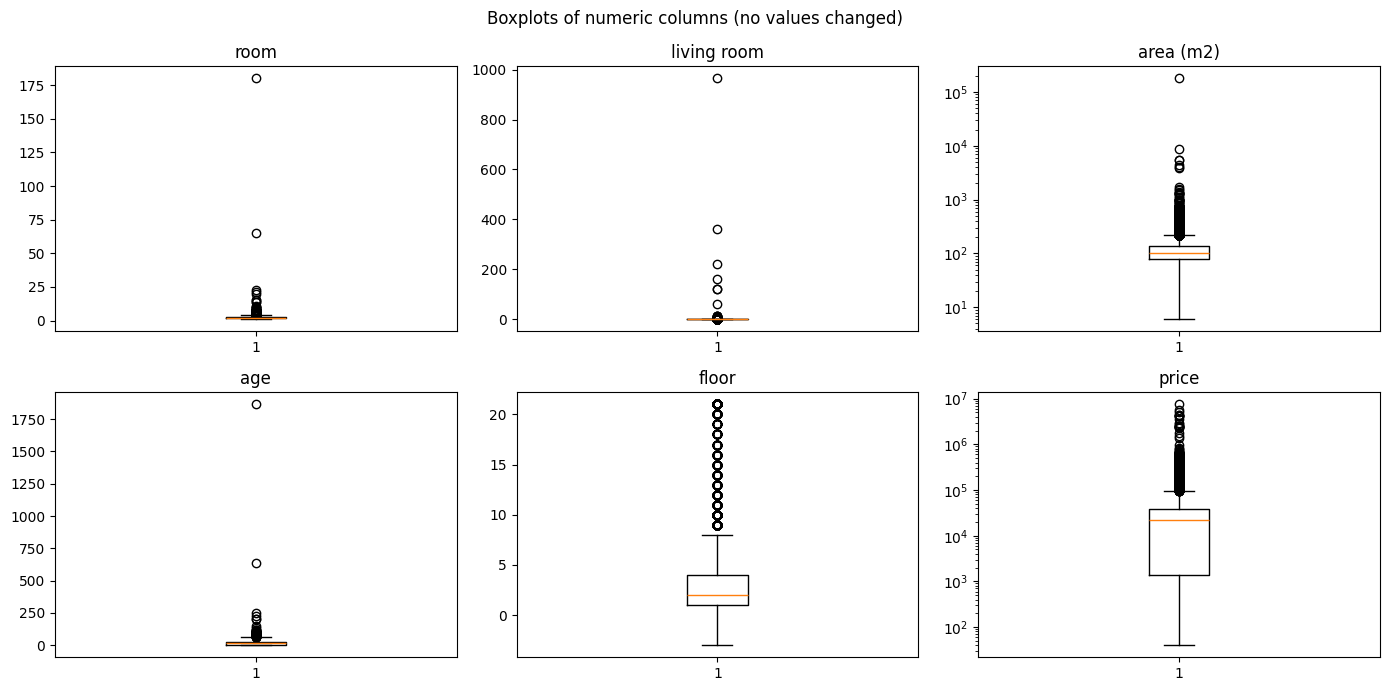

Skewness of price: raw = 24.2 | after log10 = -0.78
Median area, high-price flats : 235.0 m2
Median area, other flats      : 100.0 m2
Share of high-price flats in the 6 most expensive districts: 0.66 | share of all flats in those districts: 0.24
Highest price per m2 in the dataset: 55500 TL/m2

Flats with area > 205 m2: 936 | of them with 4+ rooms: 651
Flats with 5+ rooms, by number of rooms: {np.int64(5): 202, np.int64(6): 60, np.int64(7): 25, np.int64(8): 11, np.int64(9): 3, np.int64(10): 2, np.int64(11): 1, np.int64(14): 2, np.int64(15): 2, np.int64(20): 1, np.int64(21): 1, np.int64(23): 1, np.int64(65): 1, np.int64(180): 1}

Living room value counts: {np.int64(0): 369, np.int64(1): 10389, np.int64(2): 295, np.int64(3): 19, np.int64(4): 2, np.int64(5): 1, np.int64(10): 3, np.int64(11): 3, np.int64(12): 1, np.int64(60): 1, np.int64(121): 1, np.int64(123): 1, np.int64(160): 1, np.int64(223): 1, np.int64(363): 1, np.int64(965): 1}
Negative floors (basement): 359 | highest floor: 21
Bui

In [ ]:
# ===== D5: outliers =====
# We do not delete or cap the outliers just because they are extreme.
# First we investigate them, and then we decide if they are real or errors.

num_cols = ["room", "living room", "area (m2)", "age", "floor", "price"]
rows_before = len(df)            # we save the size to check at the end that no row was lost

# DETECT (IQR rule)
# IQR = Q3 - Q1. A value is flagged if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
# We use the IQR rule because it does not need a normal distribution, and rent data is skewed.
report = []
for col in num_cols:
    s = df[col].astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    report.append({"column": col, "lower limit": low, "upper limit": high,
                   "below": int((s < low).sum()), "above": int((s > high).sum()),
                   "flagged": int(((s < low) | (s > high)).sum()),
                   "% flagged": round(((s < low) | (s > high)).mean() * 100, 1),
                   "min": s.min(), "max": s.max()})
outlier_report = pd.DataFrame(report)
display(outlier_report)

# DETECT (boxplots)
# One boxplot for each numeric column. Area and price are on a log scale because they are very skewed,
# and on a normal scale the box becomes flat and we cannot read it.
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    ax.boxplot(df[col].astype(float), vert=True)
    ax.set_title(col)
    if col in ["area (m2)", "price"]:
        ax.set_yscale("log")
plt.suptitle("Boxplots of numeric columns (no values changed)")
plt.tight_layout()
plt.show()

# EXPLAIN
# Now we check if the extreme values are real or errors.
# (a) Price: are the expensive flats just big flats in expensive districts?
print("Skewness of price: raw =", round(df["price"].skew(), 1),
      "| after log10 =", round(np.log10(df["price"]).skew(), 2))
high_price = df["price"] > outlier_report.loc[outlier_report["column"] == "price", "upper limit"].iloc[0]
print("Median area, high-price flats :", df.loc[high_price, "area (m2)"].median(), "m2")
print("Median area, other flats      :", df.loc[~high_price, "area (m2)"].median(), "m2")
top6 = df.groupby("district")["price"].median().nlargest(6).index
print("Share of high-price flats in the 6 most expensive districts:",
      round(df.loc[high_price, "district"].isin(top6).mean(), 2),
      "| share of all flats in those districts:", round(df["district"].isin(top6).mean(), 2))
print("Highest price per m2 in the dataset:", round((df["price"] / df["area (m2)"]).max()), "TL/m2")

# (b) Area and room: do the big flats also have many rooms?
big = df["area (m2)"] > 205
print("\nFlats with area > 205 m2:", big.sum(), "| of them with 4+ rooms:", (big & (df["room"] >= 4)).sum())
print("Flats with 5+ rooms, by number of rooms:", df.loc[df["room"] >= 5, "room"].value_counts().sort_index().to_dict())

# (c) Living room: the IQR rule does not work well here
print("\nLiving room value counts:", df["living room"].value_counts().sort_index().to_dict())

# (d) Floor and age
print("Negative floors (basement):", (df["floor"] < 0).sum(), "| highest floor:", df["floor"].max())
print("Buildings older than 100 years:", (df["age"] > 100).sum(),
      "| districts:", df.loc[df["age"] > 100, "district"].value_counts().to_dict())


#               Price is also our target, so capping it would hide what the model has to learn.
#               We will deal with the skew later using a log transform of the target.
# area, room  : we keep them. Big flats have many rooms, so area and rooms agree with each other.
# living room : we keep it. 94% of the flats have 1, so the IQR is 0 and every other value is flagged.
#               This is a problem of the rule, not an error in the data.
# floor, age  : we keep them. Floors up to 21 are possible in high-rise buildings, negative floors are basements,
#               and the oldest buildings are mostly in Beyoglu, which is a historic district.


# FIX
# We do not cap or remove anything. We only save the outlier report.
outlier_report.to_csv("outlier_report.csv", index=False)

# VERIFY
assert len(df) == rows_before, "rows changed in the outlier step"
print("\nVERIFY OK: no rows removed or changed, shape =", df.shape)


In [ ]:
#Checks for identifiers and irrelevant Variable
print("=== ORIGINAL DATASET ===")
print("Total columns:", df.shape[1])
print(df.columns.tolist())

# 2. Detect & Explain: Check cardinality (number of unique values per column)
# High cardinality columns relative to dataset length often indicate IDs or row identifiers.
print("\n=== UNIQUENESS CHECK (High cardinality = potential ID) ===")
print(df.nunique())

# 3. Decide: Identify irrelevant or ID columns to remove
# (Based on domain inspection, district/neighborhood are categorical features,
# while things like unnamed index columns or pure row IDs would be dropped here)
columns_to_drop = [] # Add any column names if an ID column exists (e.g., ['Unnamed: 0', 'id'])

# 4. Fix: Drop irrelevant columns if any are identified
df_cleaned = df.drop(columns=columns_to_drop)

# 5. Verify: Confirm the cleaned columns and dataset shape
print("\n=== VERIFICATION ===")
print("Columns kept for modeling:", df_cleaned.columns.tolist())
print("Final number of columns:", df_cleaned.shape[1])

=== ORIGINAL DATASET ===
Total columns: 8
['district', 'neighborhood', 'room', 'living room', 'area (m2)', 'age', 'floor', 'price']

=== UNIQUENESS CHECK (High cardinality = potential ID) ===
district         38
neighborhood    590
room             18
living room      16
area (m2)       325
age              80
floor            25
price           643
dtype: int64

=== VERIFICATION ===
Columns kept for modeling: ['district', 'neighborhood', 'room', 'living room', 'area (m2)', 'age', 'floor', 'price']
Final number of columns: 8


In [ ]:
# Separate predictors from the target
X = df_cleaned.drop(columns=["price"])
y = df_cleaned["price"]

print("=== TARGET LEAKAGE CHECK ===")
print("Target variable name:", y.name)
print("Number of predictors:", X.shape[1])

# Check the meaning and origin of the predictors:
# These features describe the apartment and are available
# before predicting its rental price.
# None of them is calculated using price.

print("Predictors:", X.columns.tolist())

# Correlations describe relationships, but do not prove leakage
numeric_cols = X.select_dtypes(include=["number"]).columns

correlations = df_cleaned[
    numeric_cols.tolist() + ["price"]
].corr()["price"].sort_values(ascending=False)

print("\n--- Correlation of Numeric Features with Target ---")
print(correlations)

# Verify that the target is not included in X
print("\n=== VERIFICATION ===")
assert "price" not in X.columns

print("Final predictors shape (X):", X.shape)
print("Is 'price' absent from predictors?", "price" not in X.columns)

=== TARGET LEAKAGE CHECK ===
Target variable name: price
Number of predictors: 7
Predictors: ['district', 'neighborhood', 'room', 'living room', 'area (m2)', 'age', 'floor']

--- Correlation of Numeric Features with Target ---
price          1.000000
floor          0.096461
room           0.076741
area (m2)      0.019651
living room   -0.001389
age           -0.022770
Name: price, dtype: float64

=== VERIFICATION ===
Final predictors shape (X): (11089, 7)
Is 'price' absent from predictors? True


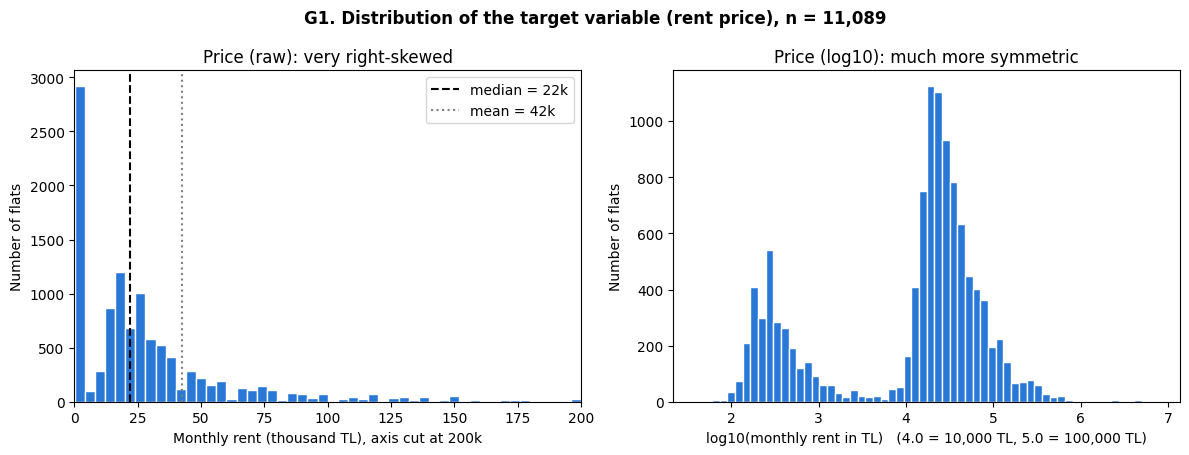

Skewness of price (raw)  : 24.2
Skewness of price (log10): -0.78
Median: 22000.0 | Mean: 42304 | Max: 7500000
Flats above 200k TL (not shown in the left panel): 279


In [ ]:
# G1: distribution of the target variable (price)
# we draw two histograms of price side by side the raw price and the log10 of the price.

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

CUT = 200
shown = df.loc[df["price"] / 1000 <= CUT, "price"] / 1000
n_out = int((df["price"] / 1000 > CUT).sum())
axes[0].hist(shown, bins=50, color="#2a78d6", edgecolor="white")
axes[0].set_xlim(0, CUT)
axes[0].set_title("Price (raw): very right-skewed")
axes[0].set_xlabel("Monthly rent (thousand TL), axis cut at 200k")
axes[0].set_ylabel("Number of flats")

med, mean = df["price"].median() / 1000, df["price"].mean() / 1000
axes[0].axvline(med, color="black", linestyle="--", label=f"median = {med:,.0f}k")
axes[0].axvline(mean, color="gray", linestyle=":", label=f"mean = {mean:,.0f}k")
axes[0].legend()

axes[1].hist(np.log10(df["price"]), bins=60, color="#2a78d6", edgecolor="white")
axes[1].set_title("Price (log10): much more symmetric")
axes[1].set_xlabel("log10(monthly rent in TL)   (4.0 = 10,000 TL, 5.0 = 100,000 TL)")
axes[1].set_ylabel("Number of flats")

fig.suptitle(f"G1. Distribution of the target variable (rent price), n = {len(df):,}", fontweight="bold")
plt.tight_layout()
plt.show()

print("Skewness of price (raw)  :", round(df["price"].skew(), 1))
print("Skewness of price (log10):", round(np.log10(df["price"]).skew(), 2))
print("Median:", df["price"].median(), "| Mean:", round(df["price"].mean()), "| Max:", df["price"].max())
print("Flats above 200k TL (not shown in the left panel):", n_out)

#What we see:Most flats rent between about 15k and 30k TL
#Link to our questions:The large difference between flats is what Q1, Q2 and Q3 try to explain. Because of the skew, the next graphs compare medians or use a log scale

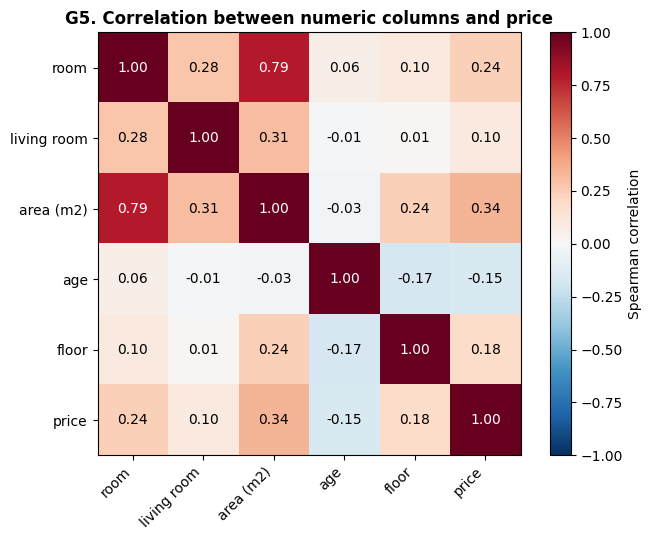

area (m2)      0.34
room           0.24
floor          0.18
age           -0.15
living room    0.10
Name: price, dtype: float64


In [ ]:
# G5: correlation heatmap (numeric columns and price)
#we calculate the correlation between every pair of numeric columns and show it as a heatmap
#it shows which variables move with the rent (our target) and which variables are related to each other

num_cols = ["room", "living room", "area (m2)", "age", "floor", "price"]
corr = df[num_cols].astype(float).corr(method="spearman").round(2)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticklabels(num_cols)

for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if abs(v) > 0.6 else "black", fontsize=10)

plt.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("G5. Correlation between numeric columns and price", fontweight="bold")
plt.tight_layout()
plt.show()

print(corr["price"].drop("price").sort_values(key=abs, ascending=False))

#What we see:Area has the strongest relation with price (0.34), then room (0.24) and floor (0.18) Age has a negative relation (−0.15)
# so newer buildings tend to rent for more Living room is weak (0.10). Area and room are strongly related to each other (0.79)

#Answer to Q1 and Q2:Bigger flats with more rooms rent for more (Q1) Higher
#floors rent for more and older buildings rent for less (Q2)